# Module 06 — Automatic Differentiation and Backpropagation

This notebook builds the machinery behind `loss.backward()` from nothing but Python and NumPy.
You will measure the accuracy of finite differences, draw a computational graph, run forward-mode
differentiation with dual numbers, write a scalar autograd engine, train a neural network with it,
re-derive the same gradients with matrix rules, and learn to *check* any gradient numerically.

Read the [concept guide](README.md) first, or keep it open alongside: the section numbers below
match its numbered concepts.

In [1]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. Three ways to get a derivative

Symbolic differentiation returns a formula, numerical differentiation nudges the input, and
automatic differentiation applies the chain rule to the program's own arithmetic. The numerical
route is the one with a tuning knob. For a step $h$,

$$
D^{+}_h f(x) = \frac{f(x+h) - f(x)}{h} = f'(x) + O(h), \qquad
D^{c}_h f(x) = \frac{f(x+h) - f(x-h)}{2h} = f'(x) + O(h^2),
$$

but both also carry a round-off error of order $\varepsilon |f(x)| / h$ with $\varepsilon \approx 2.2\times10^{-16}$.
Truncation error falls with $h$, round-off error rises, so there is a best $h$ and an accuracy floor.
Let us measure both for $f(x) = x^3$ at $x = 2$, where $f'(2) = 12$ exactly.

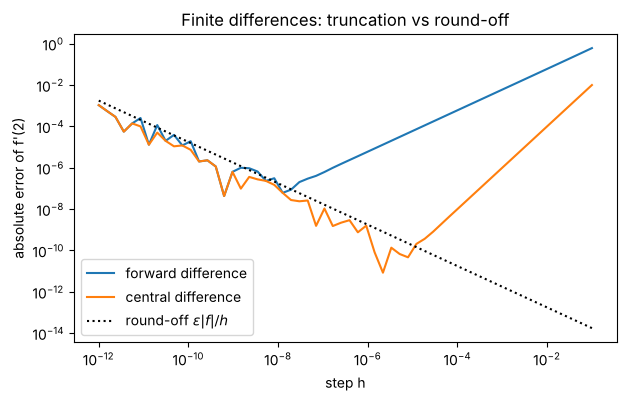

h=  1e-01  forward=12.6100000000  central=12.0100000000
h=  1e-05  forward=12.0000600003  central=12.0000000002
h=  1e-08  forward=11.9999999271  central=11.9999998827
h=  1e-12  forward=12.0010668070  central=12.0010668070
best achievable: forward ~1e-8 around h=1e-8, central ~1e-10 around h=1e-5
automatic differentiation of x**3 at 2 gives 3*x**2 = 12.0 with no h at all


In [2]:
f = lambda x: x**3
x0, exact = 2.0, 12.0
hs = np.logspace(-12, -1, 60)
err_fwd = np.array([abs((f(x0 + h) - f(x0)) / h - exact) for h in hs])
err_ctr = np.array([abs((f(x0 + h) - f(x0 - h)) / (2 * h) - exact) for h in hs])

plt.loglog(hs, err_fwd, label="forward difference")
plt.loglog(hs, err_ctr, label="central difference")
plt.loglog(hs, 2.2e-16 * abs(f(x0)) / hs, "k:", label=r"round-off $\varepsilon|f|/h$")
plt.xlabel("step h"); plt.ylabel("absolute error of f'(2)")
plt.title("Finite differences: truncation vs round-off"); plt.legend(); plt.show()

for h in (1e-1, 1e-5, 1e-8, 1e-12):
    fwd = (f(x0 + h) - f(x0)) / h
    ctr = (f(x0 + h) - f(x0 - h)) / (2 * h)
    print(f"h={h:7.0e}  forward={fwd:.10f}  central={ctr:.10f}")
print("best achievable: forward ~1e-8 around h=1e-8, central ~1e-10 around h=1e-5")
print("automatic differentiation of x**3 at 2 gives 3*x**2 =", 3 * x0**2, "with no h at all")

Notice the V shape. Left of the minimum the two evaluations of $f$ agree to almost all their
digits and the subtraction destroys the rest; right of it the Taylor remainder dominates. Central
differences buy two orders of magnitude at the price of one extra evaluation per input — and a
*full gradient* costs $2n$ evaluations for $n$ inputs. Keep this plot in mind: it is why finite
differences are a *test*, not a training method, and why gradient checks (Section 7) use
$h \approx 10^{-5}$ in float64.

**Try it yourself:** repeat the experiment with `np.float32(x0)` and `np.float32(h)`. Where does
the floor move to, and what does that imply for gradient checks in single precision?

## 2. Computational graphs

An expression becomes a directed acyclic graph: inputs are leaves, every primitive operation is a
node, and an edge means "this value is used by that operation". Evaluating the nodes in a
*topological order* (every node after its parents) is the forward pass. Here is the squared error
of a one-feature linear model, $L = (wx + b - y)^2$, with $w=2,\ x=3,\ b=1,\ y=5$.

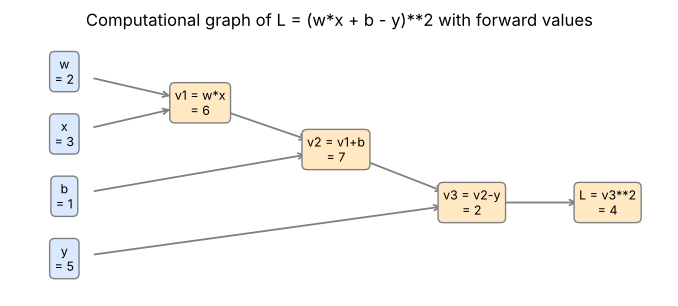

topological order: ['w', 'x', 'b', 'y', 'v1 = w*x', 'v2 = v1+b', 'v3 = v2-y', 'L = v3**2']
forward values   : [2.0, 3.0, 1.0, 5.0, 6.0, 7.0, 2.0, 4.0]


In [3]:
w, x, b, y = 2.0, 3.0, 1.0, 5.0
v1 = w * x          # 6
v2 = v1 + b         # 7
v3 = v2 - y         # 2
L = v3 ** 2         # 4
vals = {"w": w, "x": x, "b": b, "y": y, "v1 = w*x": v1, "v2 = v1+b": v2, "v3 = v2-y": v3, "L = v3**2": L}
pos = {"w": (0, 3), "x": (0, 2), "b": (0, 1), "y": (0, 0),
       "v1 = w*x": (2, 2.5), "v2 = v1+b": (4, 1.75), "v3 = v2-y": (6, 0.9), "L = v3**2": (8, 0.9)}
edges = [("w", "v1 = w*x"), ("x", "v1 = w*x"), ("v1 = w*x", "v2 = v1+b"), ("b", "v2 = v1+b"),
         ("v2 = v1+b", "v3 = v2-y"), ("y", "v3 = v2-y"), ("v3 = v2-y", "L = v3**2")]

fig, ax = plt.subplots(figsize=(8.5, 3.4))
for a, c in edges:
    ax.annotate("", xy=pos[c], xytext=pos[a],
                arrowprops=dict(arrowstyle="->", lw=1.3, shrinkA=22, shrinkB=22, color="gray"))
for name, (px, py) in pos.items():
    leaf = len(name) == 1
    ax.text(px, py, f"{name}\n= {vals[name]:g}", ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.4", fc="#dbe9ff" if leaf else "#ffe8c2", ec="gray"))
ax.set_xlim(-0.8, 8.9); ax.set_ylim(-0.6, 3.6); ax.axis("off")
ax.set_title("Computational graph of L = (w*x + b - y)**2 with forward values")
plt.show()

print("topological order:", [k for k in vals])
print("forward values   :", [vals[k] for k in vals])

Blue leaves are inputs, orange nodes are operations. The graph does not depend on the numbers:
feed it a different data point and the *structure* is identical, which is why a framework can run
one generic backward routine for every example. A spreadsheet's dependency graph, the dataflow
of a cost model, and the `grad_fn` chain PyTorch attaches to every tensor are all this picture.

## 3. The chain rule on graphs: forward mode and reverse mode

Each edge carries a *local* derivative. **Forward mode** pushes tangents $\dot v_i = \partial v_i / \partial x_j$
from one chosen input towards the output; **reverse mode** pulls adjoints $\bar v_k = \partial L / \partial v_k$
from the output back to every input:

$$
\dot v_i = \sum_{k \in \mathrm{pa}(i)} \frac{\partial \phi_i}{\partial v_k}\,\dot v_k, \qquad
\bar v_k = \sum_{i \in \mathrm{ch}(k)} \bar v_i\,\frac{\partial \phi_i}{\partial v_k}.
$$

Forward mode has a beautiful implementation: **dual numbers**. Carry the pair $(v, \dot v)$ through
every operation with the product rule built in, $(a,\dot a)(b,\dot b) = (ab,\ a\dot b + \dot a b)$, and the
derivative pops out of the computation with no graph stored at all.

In [4]:
class Dual:
    # a value together with its tangent (derivative w.r.t. one chosen input)
    def __init__(self, val, dot=0.0):
        self.val, self.dot = float(val), float(dot)
    def _lift(o):
        return o if isinstance(o, Dual) else Dual(o)
    def __add__(self, o):
        o = Dual._lift(o); return Dual(self.val + o.val, self.dot + o.dot)
    def __sub__(self, o):
        o = Dual._lift(o); return Dual(self.val - o.val, self.dot - o.dot)
    def __mul__(self, o):
        o = Dual._lift(o); return Dual(self.val * o.val, self.val * o.dot + self.dot * o.val)
    def __pow__(self, k):
        return Dual(self.val ** k, k * self.val ** (k - 1) * self.dot)
    def exp(self):
        e = math.exp(self.val); return Dual(e, e * self.dot)
    def sin(self):
        return Dual(math.sin(self.val), math.cos(self.val) * self.dot)
    __radd__, __rmul__ = __add__, __mul__
    def __repr__(self):
        return f"Dual(val={self.val:.6g}, dot={self.dot:.6g})"

# f(x1, x2) = (x1*x2 + x1)**2 at (2, 3): closed form df/dx1 = 2*x1*(x2+1)**2 = 64, df/dx2 = 2*x1**2*(x2+1) = 32
def f(x1, x2):
    return (x1 * x2 + x1) ** 2

sweep1 = f(Dual(2.0, 1.0), Dual(3.0, 0.0))   # seed x1
sweep2 = f(Dual(2.0, 0.0), Dual(3.0, 1.0))   # seed x2
print("sweep seeded at x1:", sweep1, " -> df/dx1 =", sweep1.dot)
print("sweep seeded at x2:", sweep2, " -> df/dx2 =", sweep2.dot)

g = lambda x: x * x.exp() + x.sin()           # g'(x) = e^x (1 + x) + cos x
d = g(Dual(1.0, 1.0))
print(f"g'(1) by dual numbers = {d.dot:.12f}, closed form = {math.e * 2 + math.cos(1.0):.12f}")

sweep seeded at x1: Dual(val=64, dot=64)  -> df/dx1 = 64.0
sweep seeded at x2: Dual(val=64, dot=32)  -> df/dx2 = 32.0
g'(1) by dual numbers = 5.976865962786, closed form = 5.976865962786


Two sweeps were needed for two inputs: forward mode costs one pass **per input**. Reverse mode
runs the arrows backwards, starting from $\bar L = 1$, and costs one pass **per output**. By hand on
the same graph ($v_1 = x_1 x_2 = 6$, $v_2 = v_1 + x_1 = 8$, $v_3 = v_2^2 = 64$):

$\bar v_3 = 1$, $\ \bar v_2 = 2 v_2 = 16$, $\ \bar v_1 = 16$, $\ \bar x_1 = \bar v_1 x_2 + \bar v_2 \cdot 1 = 48 + 16 = 64$, $\ \bar x_2 = \bar v_1 x_1 = 32$.

One sweep, both derivatives — and $x_1$, which is used twice, correctly collects two contributions.
For a loss with millions of parameters and one output this is the whole game: the full gradient
costs a small constant times one forward pass, not millions of them. We will *measure* this once
we have a reverse-mode engine (Section 5).

**Try it yourself:** add `__truediv__` to `Dual` using the quotient rule and check $\frac{d}{dx}\,\frac{\sin x}{x}$ at $x = 2$ against the closed form $\frac{x\cos x - \sin x}{x^2}$.

## 4. Backpropagation: reverse mode on a neural network

For layers $z_l = W_l a_{l-1} + b_l$, $a_l = f(z_l)$, reverse mode has a regular structure. With
$\delta_l := \partial\mathcal{L}/\partial z_l$:

$$
\delta_L = \nabla_{a_L}\mathcal{L} \odot f'(z_L), \qquad
\delta_l = (W_{l+1}^\top \delta_{l+1}) \odot f'(z_l), \qquad
\frac{\partial \mathcal{L}}{\partial W_l} = \delta_l a_{l-1}^\top, \qquad
\frac{\partial \mathcal{L}}{\partial b_l} = \delta_l .
$$

The concept guide works a 2–2–1 ReLU network by hand (input $x=(1,2)$, target $y=3$, squared loss).
Let us reproduce every number.

In [5]:
relu = lambda z: np.maximum(z, 0.0)
drelu = lambda z: (z > 0).astype(float)

W1 = np.array([[1.0, -1.0], [0.0, 1.0]]); b1 = np.zeros(2)
W2 = np.array([[1.0, 0.5]]);              b2 = np.zeros(1)
x = np.array([1.0, 2.0]); y_target = 3.0

# forward
z1 = W1 @ x + b1; a1 = relu(z1)
z2 = W2 @ a1 + b2; y_hat = z2[0]          # linear output
loss = 0.5 * (y_hat - y_target) ** 2
print(f"z1={z1}, a1={a1}, y_hat={y_hat}, loss={loss}")

# backward
delta2 = np.array([y_hat - y_target])          # dL/dz2 for a linear output with squared loss
dW2 = np.outer(delta2, a1); db2 = delta2
delta1 = (W2.T @ delta2) * drelu(z1)
dW1 = np.outer(delta1, x);  db1 = delta1
print("delta2 =", delta2, " dW2 =", dW2, " db2 =", db2)
print("delta1 =", delta1)
print("dW1 =\n", dW1, "\ndb1 =", db1)

z1=[-1.  2.], a1=[0. 2.], y_hat=1.0, loss=2.0
delta2 = [-2.]  dW2 = [[-0. -4.]]  db2 = [-2.]
delta1 = [-0. -1.]
dW1 =
 [[-0. -0.]
 [-1. -2.]] 
db1 = [-0. -1.]


The first hidden unit had $z_1 = -1 < 0$, so its ReLU derivative is 0 and *every* gradient that
flows through it is 0: its weights and bias will not move. That is the "dying ReLU" problem in
two lines of arithmetic. Also note what had to be kept from the forward pass: $a_1$ (for $\partial\mathcal{L}/\partial W_2$)
and $z_1$ (for the mask). In a deep network this stored-activation memory, not the weights,
dominates training memory. (A leaky ReLU, with derivative `np.where(z > 0, 1.0, 0.01)`, would let the dead
unit receive a small gradient and recover.)

## 5. A scalar autograd engine from scratch

Now the real thing. A `Value` remembers its `data`, its `grad`, the `Value`s it was made from, and a
tiny closure `_backward` that passes its gradient to its parents using the local derivative rule.
Operator overloading builds the graph silently as you write ordinary arithmetic; `backward()`
sorts the graph topologically, seeds the output with gradient 1 and calls every closure in
reverse order. This is the design of Karpathy's `micrograd` and, in spirit, of PyTorch's autograd.

| op | local rule in the closure (`g` is the gradient arriving at `out`) |
|---|---|
| `a + b` | `a.grad += g; b.grad += g` |
| `a * b` | `a.grad += b.data*g; b.grad += a.data*g` |
| `a ** k` | `a.grad += k*a.data**(k-1)*g` |
| `exp`, `log` | `a.grad += out.data*g`, `a.grad += g/a.data` |
| `tanh`, `relu` | `a.grad += (1-out.data**2)*g`, `a.grad += (a.data>0)*g` |

Gradients **accumulate** (`+=`): a node used twice must receive both contributions. The flip side
is that you must zero all `grad`s before every new `backward()`.

In [6]:
class Value:
    # a scalar that remembers how it was computed, and how to pass a gradient back
    def __init__(self, data, _parents=(), _op=""):
        self.data = float(data)
        self.grad = 0.0
        self._parents = _parents
        self._op = _op
        self._backward = lambda g: None     # receives dL/d(out) and adds to the parents' grads

    def __repr__(self):
        return f"Value(data={self.data:.4g}, grad={self.grad:.4g})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward(g):
            self.grad += g
            other.grad += g
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward(g):
            self.grad += other.data * g
            other.grad += self.data * g
        out._backward = _backward
        return out

    def __pow__(self, k):
        assert isinstance(k, (int, float)), "only constant exponents"
        out = Value(self.data ** k, (self,), f"**{k}")
        def _backward(g):
            self.grad += k * self.data ** (k - 1) * g
        out._backward = _backward
        return out

    def exp(self):
        e = math.exp(self.data)
        out = Value(e, (self,), "exp")
        def _backward(g):
            self.grad += e * g                       # d/da e^a = e^a = the output
        out._backward = _backward
        return out

    def log(self):
        out = Value(math.log(self.data), (self,), "log")
        def _backward(g):
            self.grad += (1.0 / self.data) * g       # needs the *input*
        out._backward = _backward
        return out

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), "tanh")
        def _backward(g):
            self.grad += (1.0 - t ** 2) * g          # needs the *output*
        out._backward = _backward
        return out

    def relu(self):
        out = Value(self.data if self.data > 0 else 0.0, (self,), "relu")
        def _backward(g):
            self.grad += (1.0 if self.data > 0 else 0.0) * g
        out._backward = _backward
        return out

    # convenience operators, all expressed through the primitives above
    def __neg__(self):            return self * -1.0
    def __radd__(self, other):    return self + other
    def __sub__(self, other):     return self + (-other)
    def __rsub__(self, other):    return other + (-self)
    def __rmul__(self, other):    return self * other
    def __truediv__(self, other): return self * other ** -1
    def __rtruediv__(self, other):return other * self ** -1

    def topo_order(self):
        order, seen = [], set()
        def visit(v):
            if v not in seen:
                seen.add(v)
                for p in v._parents:
                    visit(p)
                order.append(v)          # a node is appended only after all its parents
        visit(self)
        return order

    def backward(self):
        order = self.topo_order()
        self.grad = 1.0
        for v in reversed(order):
            v._backward(v.grad)          # hand each node's complete gradient to its parents

print("Value engine ready:", Value(2.0) * 3 + 1)

Value engine ready: Value(data=7, grad=0)


In [7]:
# Section 2's graph, now differentiated automatically
w, x, b, y = Value(2.0), Value(3.0), Value(1.0), Value(5.0)
L = (w * x + b - y) ** 2
L.backward()
print(f"L = {L.data},  dL/dw = {w.grad},  dL/dx = {x.grad},  dL/db = {b.grad},  dL/dy = {y.grad}")
print("closed form: dL/dw = 2*(wx+b-y)*x =", 2 * (2 * 3 + 1 - 5) * 3, ", dL/db = 2*(wx+b-y) =", 2 * (2 * 3 + 1 - 5))

print("\ntopological order (op: data):")
for v in L.topo_order():
    print(f"   {v._op or 'leaf':6s} data={v.data:6.1f}  grad={v.grad:6.1f}")

L = 4.0,  dL/dw = 12.0,  dL/dx = 8.0,  dL/db = 4.0,  dL/dy = -4.0
closed form: dL/dw = 2*(wx+b-y)*x = 12 , dL/db = 2*(wx+b-y) = 4

topological order (op: data):
   leaf   data=   2.0  grad=  12.0
   leaf   data=   3.0  grad=   8.0
   *      data=   6.0  grad=   4.0
   leaf   data=   1.0  grad=   4.0
   +      data=   7.0  grad=   4.0
   leaf   data=   5.0  grad=  -4.0
   leaf   data=  -1.0  grad=  20.0
   *      data=  -5.0  grad=   4.0
   +      data=   2.0  grad=   4.0
   **2    data=   4.0  grad=   1.0


The order lists leaves first and the loss last; `backward()` walks it in reverse so that every
node's gradient is complete before it is passed on. The `-1.0` leaf and the `*` node with value $-5$
are what `__sub__` creates (`a - b` is implemented as `a + b * (-1)`) — a reminder that the engine
differentiates the program *as written*, constants and all.

Now the step you should never skip: compare with central differences. We write a helper that
evaluates an expression on plain floats, perturbs one input at a time, and reports the relative error.

In [8]:
def expression(a, b, c):
    # works on floats and on Values alike (that is the point of operator overloading)
    return (a * b + c.exp()).tanh() * (a ** 2 / (b + 3.0)) + (b * c).log()

def numerical_grad(fn, args, h=1e-5):
    grads = []
    for i in range(len(args)):
        plus = list(args); plus[i] += h
        minus = list(args); minus[i] -= h
        grads.append((fn(*plus) - fn(*minus)) / (2 * h))
    return np.array(grads)

def relative_error(g, g_num):
    return np.linalg.norm(g - g_num) / (np.linalg.norm(g) + np.linalg.norm(g_num) + 1e-300)

class F:   # float wrapper so that .exp()/.tanh()/.log() exist on plain numbers too
    def __init__(self, v): self.v = float(v)
    def exp(self): return F(math.exp(self.v))
    def log(self): return F(math.log(self.v))
    def tanh(self): return F(math.tanh(self.v))
    def _l(o): return o.v if isinstance(o, F) else float(o)
    def __add__(s, o): return F(s.v + F._l(o))
    def __mul__(s, o): return F(s.v * F._l(o))
    def __pow__(s, k): return F(s.v ** k)
    def __truediv__(s, o): return F(s.v / F._l(o))
    __radd__, __rmul__ = __add__, __mul__

a, b, c = Value(0.7), Value(1.3), Value(0.4)
out = expression(a, b, c); out.backward()
g_auto = np.array([a.grad, b.grad, c.grad])
g_num = numerical_grad(lambda *t: expression(*[F(v) for v in t]).v, [0.7, 1.3, 0.4])
print("autograd   :", g_auto)
print("numerical  :", g_num)
print(f"relative error = {relative_error(g_auto, g_num):.2e}   (< 1e-7 means the engine is right)")

autograd   : [0.3251 0.7457 2.5055]
numerical  : [0.3251 0.7457 2.5055]
relative error = 9.83e-11   (< 1e-7 means the engine is right)


A relative error around $10^{-10}$ is the signature of a correct engine; a wrong closure would
show up as $10^{-2}$ or worse. We will systematise this in Section 7.

Now the promised measurement of **cost**. Take a function of $n$ inputs. Forward mode (our `Dual`)
needs $n$ sweeps, each costing $O(n)$, so $O(n^2)$ total; reverse mode (our `Value`) needs one
forward pass plus one backward sweep, $O(n)$ total.

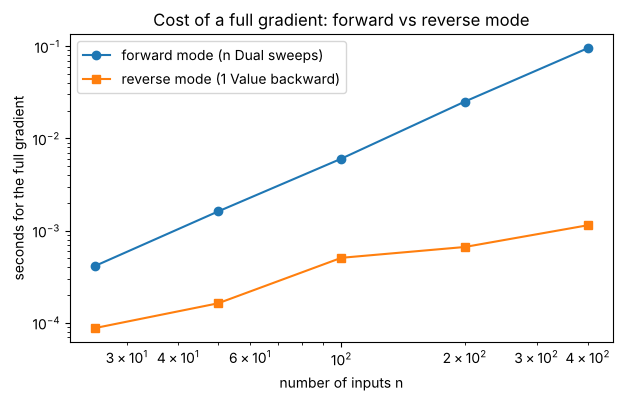

ratio forward/reverse at n=400: 84x


In [9]:
def chain(xs):
    # a function of n inputs whose graph has about 2n nodes
    acc = xs[0]
    for xi in xs[1:]:
        acc = acc * xi + xi
    return acc ** 2

ns = [25, 50, 100, 200, 400]
t_fwd, t_rev = [], []
for n in ns:
    xs = rng.uniform(0.9, 1.1, size=n)
    t0 = time.perf_counter()
    grad_fwd = np.array([chain([Dual(v, 1.0 if j == i else 0.0) for j, v in enumerate(xs)]).dot
                         for i in range(n)])                      # n sweeps
    t_fwd.append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    vs = [Value(v) for v in xs]; out = chain(vs); out.backward()   # one sweep
    grad_rev = np.array([v.grad for v in vs])
    t_rev.append(time.perf_counter() - t0)
    assert relative_error(grad_fwd, grad_rev) < 1e-10

plt.loglog(ns, t_fwd, "o-", label="forward mode (n Dual sweeps)")
plt.loglog(ns, t_rev, "s-", label="reverse mode (1 Value backward)")
plt.xlabel("number of inputs n"); plt.ylabel("seconds for the full gradient")
plt.title("Cost of a full gradient: forward vs reverse mode"); plt.legend(); plt.show()
print("ratio forward/reverse at n=400: %.0fx" % (t_fwd[-1] / t_rev[-1]))

The two curves have different slopes on the log-log plot: forward mode's time grows roughly like
$n^2$, reverse mode's like $n$, and the gap widens without bound. For a 124-million-parameter
model the ratio is not 100 but $10^8$. This is the "cheap gradient principle", and it is the
reason gradient-based deep learning is possible at all.

### Training a neural network with the engine

A neuron is a dot product plus a bias followed by a nonlinearity, all made of `Value`s; a layer is a
list of neurons; an MLP is a list of layers. We train on a synthetic two-moons dataset. For the loss we
add one *fused* operation, binary cross-entropy on the logit $s$, computed in the stable
log-sum-exp form $\max(s,0) + \log(1 + e^{-|s|}) - ys$ with the compact gradient $\sigma(s) - y$
(Sections 6 and 8 explain why frameworks fuse exactly this kind of op).

parameters: 337  (2*16+16) + (16*16+16) + (16+1) = 337


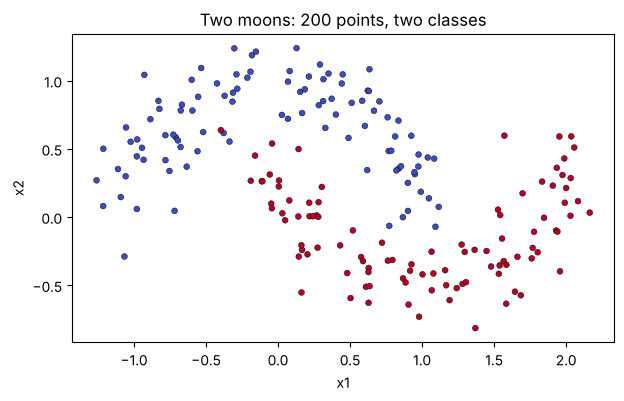

In [10]:
from sklearn.datasets import make_moons

def bce_with_logits(s, y):
    # fused, numerically stable binary cross-entropy of logit s against label y in {0, 1}
    sd = s.data
    out = Value(max(sd, 0.0) + math.log1p(math.exp(-abs(sd))) - y * sd, (s,), "bce")
    p = 1.0 / (1.0 + math.exp(-sd))
    def _backward(g):
        s.grad += (p - y) * g                   # the famous p - y
    out._backward = _backward
    return out

class Neuron:
    def __init__(self, n_in, nonlin=True):
        scale = math.sqrt(2.0 / n_in)                              # He initialisation
        self.w = [Value(rng.normal(0.0, scale)) for _ in range(n_in)]
        self.b = Value(0.0)
        self.nonlin = nonlin
    def __call__(self, xs):
        act = self.b
        for wi, xi in zip(self.w, xs):
            act = act + wi * xi
        return act.relu() if self.nonlin else act
    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, n_in, n_out, nonlin=True):
        self.neurons = [Neuron(n_in, nonlin) for _ in range(n_out)]
    def __call__(self, xs):
        return [n(xs) for n in self.neurons]
    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

class MLP:
    def __init__(self, sizes):
        self.layers = [Layer(sizes[i], sizes[i + 1], nonlin=(i < len(sizes) - 2)) for i in range(len(sizes) - 1)]
    def __call__(self, xs):
        for layer in self.layers:
            xs = layer(xs)
        return xs[0] if len(xs) == 1 else xs
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

X, y = make_moons(n_samples=200, noise=0.15, random_state=0)
model = MLP([2, 16, 16, 1])
params = model.parameters()
print("parameters:", len(params), " (2*16+16) + (16*16+16) + (16+1) =", 2 * 16 + 16 + 16 * 16 + 16 + 16 + 1)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=18, edgecolor="k", linewidth=0.3)
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("Two moons: 200 points, two classes"); plt.show()

step   0  minibatch loss 0.808  train accuracy 0.630


step  50  minibatch loss 0.333  train accuracy 0.865


step 100  minibatch loss 0.299  train accuracy 0.885


step 150  minibatch loss 0.652  train accuracy 0.895


step 200  minibatch loss 0.261  train accuracy 0.900


step 250  minibatch loss 0.199  train accuracy 0.930


step 299  minibatch loss 0.079  train accuracy 0.950
training took 17.4s with 337 parameters of pure Python


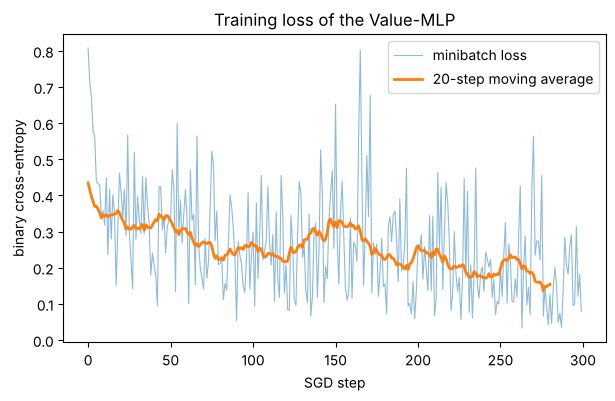

In [11]:
def batch_loss(model, idx):
    total = Value(0.0)
    for i in idx:
        total = total + bce_with_logits(model([X[i, 0], X[i, 1]]), float(y[i]))
    return total * (1.0 / len(idx))

def accuracy(model):
    scores = np.array([model([xi[0], xi[1]]).data for xi in X])
    return np.mean((scores > 0) == (y == 1))

lr, batch_size, steps = 0.2, 16, 300
loss_hist = []
t0 = time.time()
for step in range(steps):
    idx = rng.choice(len(X), size=batch_size, replace=False)
    loss = batch_loss(model, idx)
    for p in params:
        p.grad = 0.0                 # zero the accumulated gradients!
    loss.backward()
    for p in params:
        p.data -= lr * p.grad        # plain SGD
    loss_hist.append(loss.data)
    if step % 50 == 0 or step == steps - 1:
        print(f"step {step:3d}  minibatch loss {loss.data:.3f}  train accuracy {accuracy(model):.3f}")
print(f"training took {time.time() - t0:.1f}s with {len(params)} parameters of pure Python")

plt.plot(loss_hist, lw=0.8, alpha=0.5, label="minibatch loss")
plt.plot(np.convolve(loss_hist, np.ones(20) / 20, mode="valid"), lw=2, label="20-step moving average")
plt.xlabel("SGD step"); plt.ylabel("binary cross-entropy"); plt.title("Training loss of the Value-MLP")
plt.legend(); plt.show()

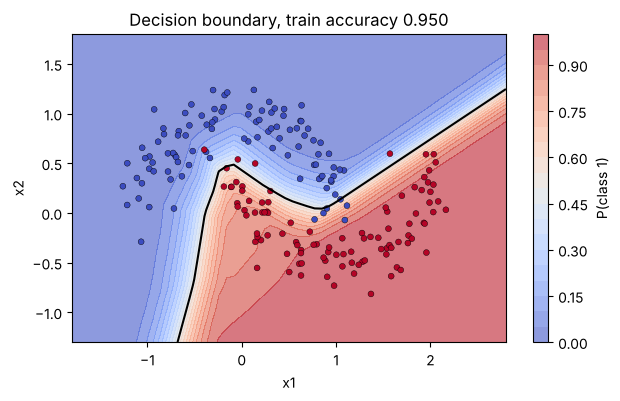

In [12]:
gx, gy = np.meshgrid(np.linspace(-1.8, 2.8, 60), np.linspace(-1.3, 1.8, 50))
scores = np.array([model([a, b_]).data for a, b_ in zip(gx.ravel(), gy.ravel())]).reshape(gx.shape)
plt.contourf(gx, gy, 1 / (1 + np.exp(-scores)), levels=20, cmap="coolwarm", alpha=0.6)
plt.colorbar(label="P(class 1)")
plt.contour(gx, gy, scores, levels=[0.0], colors="k", linewidths=1.5)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=18, edgecolor="k", linewidth=0.3)
plt.xlabel("x1"); plt.ylabel("x2"); plt.title(f"Decision boundary, train accuracy {accuracy(model):.3f}"); plt.show()

A few hundred SGD steps carve a curved boundary between the moons. Every gradient came from the
closures you read above — nothing else. The whole loop is the template of every training script:
forward, zero the gradients, backward, update.

**Try it yourself:** swap `relu` for `tanh` in `Neuron.__call__` (keep the output linear) or change
`batch_size` to 64 — how do the loss curve and the runtime change?

## 6. Vector and matrix autograd: vector-Jacobian products

A scalar engine spends most of its time in Python bookkeeping (the training loop above ran about
a thousand times slower than NumPy would). Frameworks make each *array* operation a single node
with a backward rule that maps the upstream gradient $G = \partial L / \partial Y$ to gradients of the
inputs, without ever forming a Jacobian. For the operations in our network:

| op | forward | backward |
|---|---|---|
| matmul | $Y = AB$ | $\bar A = G B^\top,\quad \bar B = A^\top G$ |
| bias broadcast | $Y = Z + \mathbf 1 b^\top$ | $\bar Z = G,\quad \bar b = G^\top \mathbf 1$ (sum over rows) |
| elementwise | $Y = f(X)$ | $\bar X = G \odot f'(X)$ |
| mean of losses | $L = \tfrac1B\sum_i \ell_i$ | $\bar\ell_i = 1/B$ |

Let us re-implement the *same* trained network with NumPy arrays, run one forward/backward pass
on a minibatch with these rules, and compare with the scalar engine's gradients, parameter by parameter.

In [13]:
# copy the trained parameters into matrices: W_l has shape (n_out, n_in)
def layer_matrices(layer):
    W = np.array([[wi.data for wi in n.w] for n in layer.neurons])
    b = np.array([n.b.data for n in layer.neurons])
    return W, b

(W1, b1), (W2, b2), (W3, b3) = [layer_matrices(l) for l in model.layers]
print("shapes:", W1.shape, b1.shape, W2.shape, b2.shape, W3.shape, b3.shape)

def sigmoid(s):
    return 1.0 / (1.0 + np.exp(-s))

def forward_backward_numpy(Xb, yb):
    B = len(Xb)
    # forward (rows are examples, so the layer map is Z = A @ W.T + b)
    Z1 = Xb @ W1.T + b1; A1 = np.maximum(Z1, 0.0)
    Z2 = A1 @ W2.T + b2; A2 = np.maximum(Z2, 0.0)
    S = (A2 @ W3.T + b3)[:, 0]                                    # logits
    loss = np.mean(np.maximum(S, 0) + np.log1p(np.exp(-np.abs(S))) - yb * S)
    # backward: upstream gradient of the mean is 1/B per example
    dS = (sigmoid(S) - yb) / B                                    # fused BCE rule, shape (B,)
    G3 = dS[:, None]                                              # dL/d(A2 @ W3.T + b3), shape (B, 1)
    dW3 = G3.T @ A2;            db3 = G3.sum(axis=0)              # matmul rule + broadcast rule
    G2 = (G3 @ W3) * (Z2 > 0)                                     # back through matmul, then ReLU mask
    dW2 = G2.T @ A1;            db2 = G2.sum(axis=0)
    G1 = (G2 @ W2) * (Z1 > 0)
    dW1 = G1.T @ Xb;            db1 = G1.sum(axis=0)
    return loss, [dW1, db1, dW2, db2, dW3, db3]

idx = rng.choice(len(X), size=32, replace=False)
loss_np, grads_np = forward_backward_numpy(X[idx], y[idx].astype(float))

# the same minibatch through the scalar engine
loss_v = batch_loss(model, idx)
for p in params:
    p.grad = 0.0
loss_v.backward()
grads_v = []
for layer in model.layers:
    grads_v.append(np.array([[wi.grad for wi in n.w] for n in layer.neurons]))
    grads_v.append(np.array([n.b.grad for n in layer.neurons]))

print(f"loss: numpy {loss_np:.10f}  scalar engine {loss_v.data:.10f}")
for name, gn, gv in zip(["dW1", "db1", "dW2", "db2", "dW3", "db3"], grads_np, grads_v):
    print(f"{name}: shape {gn.shape}, max |numpy - scalar| = {np.max(np.abs(gn - gv)):.2e}")

shapes: (16, 2) (16,) (16, 16) (16,) (1, 16) (1,)
loss: numpy 0.1094219245  scalar engine 0.1094219245
dW1: shape (16, 2), max |numpy - scalar| = 8.33e-17
db1: shape (16,), max |numpy - scalar| = 4.16e-17
dW2: shape (16, 16), max |numpy - scalar| = 7.63e-17
db2: shape (16,), max |numpy - scalar| = 1.82e-17
dW3: shape (1, 16), max |numpy - scalar| = 4.47e-17
db3: shape (1,), max |numpy - scalar| = 1.37e-17


Identical to about $10^{-16}$: the matrix rules are the scalar closures, summed over a batch and
written as matrix products. Watch the shape logic in `forward_backward_numpy`: $\bar W$ must have
$W$'s shape, so `G.T @ A` is the only arrangement that can be right; and every bias — broadcast
across the batch in the forward pass — becomes a `sum(axis=0)` in the backward pass.

### The fused softmax-cross-entropy gradient

For $K$ classes, $p = \mathrm{softmax}(z)$ and one-hot $y$, the loss $-\sum_k y_k \ln p_k$ has the gradient
$$\frac{\partial \mathcal L}{\partial z} = p - y .$$
Frameworks fuse log-softmax and the negative log-likelihood into one op for stability (no $\ln 0$),
speed (one subtraction instead of a Jacobian product) and memory (one pass over the logits, which in a
language model are the largest tensor around). Let us verify the formula against the slow route.

In [14]:
def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()

def softmax_jacobian(z):
    p = softmax(z)
    return np.diag(p) - np.outer(p, p)         # dp_i/dz_j = p_i (delta_ij - p_j)

z = np.array([2.0, 0.0, 0.0]); target = 1
y_onehot = np.eye(3)[target]
p = softmax(z)
fused = p - y_onehot
chained = softmax_jacobian(z).T @ (-y_onehot / p)   # dL/dp = -y/p, then through the softmax Jacobian
num = numerical_grad(lambda *zz: -np.log(softmax(np.array(zz))[target]), list(z))
print("p          =", p)
print("fused p - y=", fused)
print("via Jacobian", chained)
print("numerical   ", num)
print(f"relative errors: fused vs numerical {relative_error(fused, num):.1e}, Jacobian vs fused {relative_error(chained, fused):.1e}")

p          = [0.787  0.1065 0.1065]
fused p - y= [ 0.787  -0.8935  0.1065]
via Jacobian [ 0.787  -0.8935  0.1065]
numerical    [ 0.787  -0.8935  0.1065]
relative errors: fused vs numerical 3.4e-12, Jacobian vs fused 5.8e-18


Three routes, one answer: raise the logit of the correct class, lower the others, each by exactly
how wrong its probability is. The fused form needed no Jacobian and no division by $p$ — the two
things that go wrong numerically when a prediction is confidently wrong.

**Try it yourself:** set `z = np.array([30.0, 0.0, 0.0])` with `target = 1`. The fused gradient is fine;
what happens to `-y_onehot / p` on the chained route?

## 7. Gradient checking

A wrong backward rule does not crash: it trains a slightly wrong model, slowly. The defence is a
*gradient checker*: central differences on a few parameters, compared through a relative error

$$
r = \frac{\|g - \hat g\|_2}{\|g\|_2 + \|\hat g\|_2}, \qquad
r < 10^{-7} \text{ correct},\quad 10^{-7}\!-\!10^{-4} \text{ kinks},\quad > 10^{-2} \text{ bug}.
$$

We check the scalar engine on the trained network, then plant two bugs and watch the checker catch them.

In [15]:
def grad_check(model, idx, n_params=20, h=1e-5, seed=0):
    # analytic gradient of the minibatch loss
    params = model.parameters()
    for p in params:
        p.grad = 0.0
    batch_loss(model, idx).backward()
    chosen = np.random.default_rng(seed).choice(len(params), size=n_params, replace=False)
    g, g_num = [], []
    for k in chosen:
        p = params[k]
        g.append(p.grad)
        old = p.data
        p.data = old + h; lp = batch_loss(model, idx).data
        p.data = old - h; lm = batch_loss(model, idx).data
        p.data = old
        g_num.append((lp - lm) / (2 * h))
    g, g_num = np.array(g), np.array(g_num)
    return relative_error(g, g_num), g, g_num

def smallest_relu_input(model, idx):
    # how close does any hidden pre-activation in this minibatch come to ReLU's kink at 0?
    closest = np.inf
    for i in idx:
        acts = [X[i, 0], X[i, 1]]
        for layer in model.layers[:-1]:
            pre = np.array([n.b.data + sum(wi.data * a for wi, a in zip(n.w, acts)) for n in layer.neurons])
            closest = min(closest, np.min(np.abs(pre)))
            acts = list(np.maximum(pre, 0.0))
    return closest

for trial in range(5):
    idx = rng.choice(len(X), size=8, replace=False)
    r, g, g_num = grad_check(model, idx)
    print(f"minibatch {trial}: relative error {r:.1e}, closest hidden pre-activation to 0: {smallest_relu_input(model, idx):.1e}")

minibatch 0: relative error 6.8e-02, closest hidden pre-activation to 0: 1.3e-06


minibatch 1: relative error 4.7e-11, closest hidden pre-activation to 0: 3.7e-03


minibatch 2: relative error 9.6e-12, closest hidden pre-activation to 0: 6.3e-04


minibatch 3: relative error 8.7e-11, closest hidden pre-activation to 0: 4.6e-04


minibatch 4: relative error 1.3e-10, closest hidden pre-activation to 0: 3.7e-03


Relative errors around $10^{-10}$ say the engine is right. If one minibatch shows a much larger error, look at
the last column: a hidden pre-activation within about $h = 10^{-5}$ of zero means the central difference
straddled a ReLU kink, and the "error" is the kink, not the code (Section 8 shows this in isolation). That is
why a gradient check is run on several minibatches, and why a single outlier is interpreted before it is believed.

Now let us plant two bugs and watch the checker catch them.

In [16]:
# bug 1: the tanh closure uses the *input* instead of the output   (1 - a^2 instead of 1 - tanh(a)^2)
def buggy_tanh(self):
    out = Value(math.tanh(self.data), (self,), "tanh")
    def _backward(g):
        self.grad += (1.0 - self.data ** 2) * g
    out._backward = _backward
    return out

# bug 2: the multiplication closure forgets to swap the operands
def buggy_mul(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), "*")
    def _backward(g):
        self.grad += self.data * g
        other.grad += other.data * g
    out._backward = _backward
    return out

def check_expression(fn, point, label):
    vs = [Value(v) for v in point]
    out = fn(*vs); out.backward()
    g = np.array([v.grad for v in vs])
    g_num = numerical_grad(lambda *t: fn(*[F(v) for v in t]).v, list(point))
    print(f"{label:38s} relative error = {relative_error(g, g_num):.1e}")

expr = lambda a, b: (a * b).tanh() + a * a
good_tanh, good_mul = Value.tanh, Value.__mul__
check_expression(expr, [0.3, 0.2], "correct engine")
Value.tanh = buggy_tanh
check_expression(expr, [0.3, 0.2], "buggy tanh, small inputs")
check_expression(expr, [1.5, 1.2], "buggy tanh, larger inputs")
Value.tanh = good_tanh
Value.__mul__ = buggy_mul
check_expression(expr, [0.3, 0.2], "buggy mul")
Value.__mul__ = good_mul
check_expression(expr, [0.3, 0.2], "repaired engine")

correct engine                         relative error = 6.4e-13
buggy tanh, small inputs               relative error = 1.8e-06
buggy tanh, larger inputs              relative error = 6.9e-01
buggy mul                              relative error = 7.9e-02
repaired engine                        relative error = 6.4e-13


The multiplication bug is loud at any point. The `tanh` bug is nearly invisible near zero (where
$1 - a^2 \approx 1 - \tanh^2 a$) and glaring for larger inputs — which is why you check at several
points and parameter scales, not just at a small random initialisation.

Three practical rules: check in **float64** (in float32 the floor is about $10^{-3}$, indistinguishable
from a mild bug); freeze **randomness** (dropout masks, data order) so both loss evaluations see the
same function; and expect **kinks** (ReLU, max) to produce isolated large errors when a pre-activation
sits within $h$ of zero — Section 8 shows one.

## 8. Where autodiff goes wrong

Autodiff differentiates the program you wrote, not the function you meant. Three demonstrations:
a false alarm at a ReLU kink, overflow in a naive log-sum-exp, and gradients vanishing through a
long chain of sigmoids.

**Log-sum-exp.** $\ln\sum_i e^{z_i}$ overflows once any $z_i > 709$. Subtracting $m = \max_i z_i$ fixes it
exactly: $\ln\sum_i e^{z_i} = m + \ln\sum_i e^{z_i - m}$, and every exponent is now $\le 0$.

ReLU at z=1e-06: analytic derivative 1, central difference 0.550  -> a false alarm, not a bug
naive  log-sum-exp = inf,  softmax = [nan nan nan]
stable log-sum-exp = 1000.861995,  softmax = [0.4223 0.4223 0.1554]
log-softmax of the first entry = -0.861995  (computed without ever forming p)


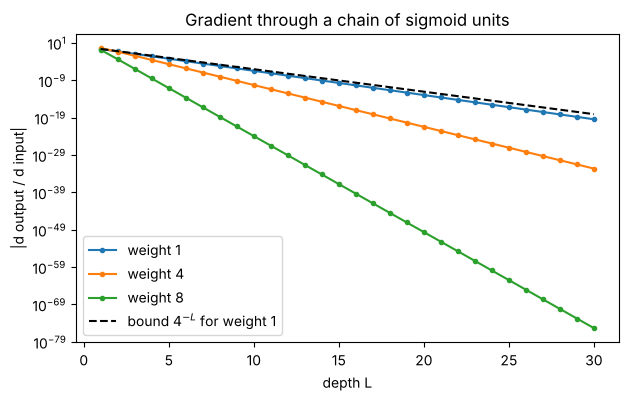

sigma' <= 1/4, so with unit weights the gradient shrinks at least like 4^-L; large weights explode instead


In [17]:
# (a) kink: central differences straddling ReLU's corner
z0, h = 1e-6, 1e-5
num = (max(z0 + h, 0) - max(z0 - h, 0)) / (2 * h)
print(f"ReLU at z={z0:g}: analytic derivative 1, central difference {num:.3f}  -> a false alarm, not a bug")

# (b) overflow and the log-sum-exp trick
z = np.array([1000.0, 1000.0, 999.0])
with np.errstate(over="ignore", invalid="ignore"):
    naive = np.log(np.sum(np.exp(z)))
    naive_softmax = np.exp(z) / np.sum(np.exp(z))
m = z.max()
stable = m + np.log(np.sum(np.exp(z - m)))
stable_softmax = np.exp(z - m) / np.sum(np.exp(z - m))
print(f"naive  log-sum-exp = {naive},  softmax = {naive_softmax}")
print(f"stable log-sum-exp = {stable:.6f},  softmax = {stable_softmax}")
print(f"log-softmax of the first entry = {z[0] - stable:.6f}  (computed without ever forming p)")

# (c) vanishing gradients through a chain of sigmoid units
def sigmoid_chain_grad(depth, weight):
    a = 0.5
    grad = 1.0
    for _ in range(depth):
        zz = weight * a
        s = 1 / (1 + np.exp(-zz))
        grad *= s * (1 - s) * weight     # local derivative of sigmoid(w*a) w.r.t. a
        a = s
    return grad

depths = np.arange(1, 31)
for wgt in (1.0, 4.0, 8.0):
    plt.semilogy(depths, [abs(sigmoid_chain_grad(d, wgt)) for d in depths], "o-", ms=3, label=f"weight {wgt:g}")
plt.semilogy(depths, 0.25 ** depths, "k--", label=r"bound $4^{-L}$ for weight 1")
plt.xlabel("depth L"); plt.ylabel("|d output / d input|"); plt.title("Gradient through a chain of sigmoid units")
plt.legend(); plt.show()
print("sigma' <= 1/4, so with unit weights the gradient shrinks at least like 4^-L; large weights explode instead")

Three different failure modes, three different remedies: interpret kinks correctly when checking
(or check away from them), always compute logarithms of sums of exponentials in the shifted form
(this is what `log_softmax` and `BCEWithLogitsLoss` do, and what our fused `bce_with_logits` did), and
control the scale of the per-layer Jacobians through initialisation, normalisation and residual
connections — the topic of Module 16.

A related operation that autodiff *cannot* help with is anything piecewise constant: rounding,
`argmax`, sampling a token. Their derivative is zero almost everywhere, so upstream parameters receive
nothing; the *straight-through estimator* substitutes the identity in the backward pass. And because
the backward pass is itself made of differentiable operations, differentiating it again gives
Hessian-vector products at the cost of about two backward passes — no $n \times n$ Hessian needed.

**Try it yourself:** in part (c) replace the sigmoid by `tanh` (derivative $1 - t^2 \le 1$) and see how
the decay changes; then by ReLU with weight 1, where the chain is exactly 1 for positive inputs.

## Summary

* Finite differences have an accuracy floor set by round-off (about $10^{-8}$ forward, $10^{-10}$ central
  in float64) and cost one or two extra evaluations **per input**; they are for testing, not training.
* A computational graph records every primitive operation; the forward pass evaluates it in topological order.
* Forward mode (dual numbers) pushes tangents, one sweep per input; reverse mode pulls adjoints, one sweep
  per output. For a scalar loss, reverse mode's cost is independent of the number of parameters — we measured it.
* Backpropagation is reverse mode on a layered network: $\delta_l = (W_{l+1}^\top\delta_{l+1})\odot f'(z_l)$,
  $\partial\mathcal L/\partial W_l = \delta_l a_{l-1}^\top$; it needs the stored activations.
* A `Value` class with `data`, `grad`, parents and a `_backward` closure, plus a topological sort, is a complete
  autograd engine. Gradients accumulate with `+=`, so zero them before every backward pass.
* Array autograd uses vector-Jacobian products: $\bar A = G B^\top$, $\bar B = A^\top G$, broadcast ⇒ sum,
  elementwise ⇒ mask; the fused softmax-cross-entropy gradient is $p - y$. Our NumPy rules matched the scalar
  engine to $10^{-16}$.
* Gradient checking with central differences and a relative error catches wrong rules in seconds — check in
  float64, at several points, away from kinks.
* Kinks, overflow (use log-sum-exp) and long chains (vanishing/exploding gradients) are where "the derivative
  of the program" stops being "the derivative you wanted".

**Next:** open `exercises.ipynb` and build the pieces yourself — a `Dual` class, the missing closures of a
`Value` engine, the matmul backward rule, a gradient checker, and finally your own trained network.